# Monitoring: the out-of-time test on 2023

This notebook tests the final model of `03_glm.ipynb` on the 2023 rows, which no earlier step used. It follows the same
yardstick as the GLM notebook (Tweedie deviance, Gini, lift and A/E) and uses aggregates only.

**The frozen model.** Two predictions are scored for every person-year. The **technical model** is the final structure, with
9 rating factors, the analysis-only factors priced at their reference level, adult age as a natural spline and the base rate
rebalanced on 2022 train. The **tariff** is its surrogate model (tariff) with five-year age bands, which is what would be
charged. Both are fitted on the 2022 train split only. The 2023 rows are scored and are never used to fit anything, except
where a later section says so and labels it as a comparison. If the model changes later, this notebook is rerun.

**Prices.** Costs of 2023 are as recorded. Costs of 2022 are on-levelled to 2023 prices with the PCE-Health index, so the two
years are on one price basis.

## Frozen model and the 2023 scoring frame

In [1]:
import pandas as pd

from health_pricing.models import glm, outofsample

pd.options.display.float_format = "{:,.3f}".format
frozen = outofsample.freeze()
oot = outofsample.load_out_of_time(frozen)
pd.DataFrame(
    {
        "model": [outofsample.TECHNICAL, outofsample.TARIFF],
        "parameters": [
            frozen.spline.model.parameters,
            frozen.final_tariff.tariff.parameters,
        ],
        "rebalancing_factor": [frozen.balance, 1.0],
    }
)

,model,parameters,rebalancing_factor
0,(a) Technical model,64,1.116
1,(a) Tariff,26,1.000


### 2023 next to 2022

The table puts 2023 next to 2022 train and test. Cost per exposure year is on the 2023 price basis. The last columns show the
cost above the large-claim cap of 100,000 dollars per person-year, which the provisional 6.5 percent load covers.

In [2]:
period_summary = outofsample.period_summary(frozen, oot)
outofsample.save_table(period_summary, "period_summary.csv")
period_summary

,period,person_years,exposure,claimants,claimant_rate,cost_per_exposure_year,mean_cost_per_claimant,claimants_above_cap,share_of_cost_above_cap,excess_load,cost_per_exposure_year_vs_2022_train
0,2022 train,17596,"17,440.750",7195,0.409,"2,183.395","5,292.570",32,0.061,0.065,0.000
1,2022 test,4151,"4,100.333",1725,0.416,"2,377.607","5,651.584",11,0.108,0.121,0.089
2,2023,18463,"18,301.250",7763,0.420,"2,551.995","6,016.320",46,0.058,0.062,0.169


The 2023 rows have 18,463 person-years and 18,301 years of exposure. Cost per exposure year is 2,552 dollars, which is 16.9
percent above 2022 train (2,183) and 7.3 percent above 2022 test (2,378). The claimant rate is 42.0 percent against 40.9
percent in train and 41.6 percent in test, and the mean cost per claimant is 6,016 dollars against 5,293 in train. So both
more people claim and each claim costs more, and the next section sorts out how much of each is the model's mix and how much
is a change in level. A total of 46 person-years in 2023 are above the cap, and the excess is 6.2 percent of capped cost,
against the provisional load of 6.5 percent.

### Levels that are new in 2023

Every 2023 level of every factor is mapped to a group with the M3 grouping. A level that the grouping had not seen would be
treated as the reference group and listed here.

In [3]:
outofsample.save_table(oot.new_levels, "new_levels_2023.csv")
print(f"Levels new in 2023: {len(oot.new_levels)}")
oot.new_levels

Levels new in 2023: 0


,factor,level,rows,treated_as


No level in 2023 is new to the grouping, so no row is moved to a reference group.

### The frozen model reproduces the GLM notebook

The technical model and the tariff are rebuilt from the 2022 train split. Their scores on train and test should equal those
saved by the GLM notebook (a test checks this to rounding).

In [4]:
scores = pd.concat(
    [
        glm.candidate_scores(
            name,
            parameters,
            {
                "train": (frozen.prepared.train, predictor(frame_train)),
                "test": (frozen.prepared.test, predictor(frame_test)),
            },
        )
        for name, parameters, predictor, frame_train, frame_test in (
            (
                outofsample.TECHNICAL,
                frozen.spline.model.parameters,
                frozen.technical,
                frozen.final_tariff.frames["spline"].train,
                frozen.final_tariff.frames["spline"].test,
            ),
            (
                outofsample.TARIFF,
                frozen.final_tariff.tariff.parameters,
                frozen.tariff,
                frozen.prepared.train,
                frozen.prepared.test,
            ),
        )
    ],
    ignore_index=True,
)
outofsample.save_table(scores.drop(columns="dropped_reason"), "frozen_model_scores_2022.csv")
scores

,candidate,split,tweedie_deviance,mean_tweedie_deviance,tweedie_deviance_p1_3,tweedie_deviance_p1_7,gini,a_e,parameters,dropped_reason
0,(a) Technical model,train,"3,031,554.108",172.287,"12,879,619.363","887,948.424",0.492,1.000,64,
1,(a) Technical model,test,"831,786.305",200.382,"3,671,617.500","231,890.463",0.386,1.081,64,
2,(a) Tariff,train,"3,051,674.804",173.430,"12,968,757.123","892,816.020",0.488,1.000,26,
3,(a) Tariff,test,"838,173.103",201.921,"3,700,064.950","233,355.176",0.378,1.081,26,


The technical model has a test deviance of 831,786 and a Gini of 0.386, and the tariff has 838,173 and 0.378. Both equal the
values saved by the GLM notebook. On train, predicted cost equals actual cost by construction (A/E of 1.000), and on the test
split A/E is 1.081.

## Frequency trend and the forecast assumption (decision gate)

Between 2022 and 2023 cost per exposure year rose 16.9 percent after on-levelling. To predict 2023 from the 2022 model, a
forecast trend has to be assumed for the claim frequency, and **it must be set without looking at 2023**. Three options are
shown.

1. **None (0 percent).** The 2022 model is used as it is.
2. **An external forecast made before 2023.** The median utilization trend for 2022 to 2023 that US insurers assumed in their plan
   year 2023 filings, from Worksheet I of the CMS Unified Rate Review public use file, weighted by member months, for inpatient and
   outpatient care. The source, its vintage and the value are recorded below.
3. **The trend that the data imply.** The 2022 to 2023 change in claim frequency measured on the same data. This is a
   **diagnostic only**. It is reported as the trend the data imply and is not used as a forecast assumption, because setting the
   trend from 2023 would make the 2023 A/E close to 1 by construction, and the out-of-time test would then test nothing.

A trend is applied as a factor on the claim hazard, so a person-year's chance of a claim becomes $1 - (1 - p)^f$ and stays below 1.
The tariff is scaled by the same factor, because it is a level charge.

In [5]:
from health_pricing.data import urr
from health_pricing.models import figures, trend

external = urr.utilization_trends(urr.read_worksheet1())
outofsample.save_table(external, "external_trend_urr.csv")
external

,market,category,filings,member_months,p25,p50,p75
0,all,inpatient,713,"275,525,046.000",0.997,1.015,1.030
1,all,outpatient,713,"275,525,046.000",1.016,1.025,1.034
2,all,blend,713,"275,525,046.000",1.008,1.019,1.031
3,individual,inpatient,285,"159,100,806.000",1.000,1.016,1.030
4,individual,outpatient,285,"159,100,806.000",1.015,1.025,1.030
5,individual,blend,285,"159,100,806.000",1.008,1.018,1.030
6,small group,inpatient,428,"116,424,240.000",0.993,1.013,1.032
7,small group,outpatient,428,"116,424,240.000",1.020,1.029,1.039
8,small group,blend,428,"116,424,240.000",1.008,1.023,1.032


### The external figure

**Source.** CMS Unified Rate Review public use file for plan year 2023, Worksheet I (file `PY2023_WKSH1_PUF_20221027.csv`, in the
archive `2023-urr-puf.zip` that CMS last updated on 1 November 2022, downloaded from `www.cms.gov/files/zip/2023-urr-puf.zip`
with its size and checksum verified). **Vintage.** The filings were made in 2022 for coverage from 2023, so the figure was
available before 2023. **Selection.** Filings with a calendar-year 2021 experience period and a projection starting on 1 January
2023, for which the Year 2 trend runs from 2022 to 2023. Filings with no member months or no entered trend are left out. Quartiles
are weighted by member months. **Value.** The median utilization trend is a rise of 1.5 percent for inpatient care and 2.5 percent
for outpatient care, and 1.9 percent when the two are blended by their shares of experience claims (quartiles 0.8 and 3.1 percent).
The table gives the figures for individual and small group filings separately.

**Limits of the figure.** It is the utilization trend that insurers assumed for the number of services per member, which is not the
same measure as the share of person-years with a claim. It is also an assumption made by US insurers, and it describes the
commercial market and not the whole population.

**Context only.** The CMS National Health Expenditure actuals for 2023, published in December 2024, show real health spending
growth of 4.4 percent in 2023 against 1.4 percent in 2022, with price growth low at 0.6 percent, so most of the growth came from the
use and intensity of services (Health Affairs, "National Health Expenditure Accounts for 2023", 18 December 2024). They were
published after 2023 and are used only to interpret the gap below. They are not a forecast input.

### Why cost per exposure year rose 16.9 percent

The ratio of 2023 to 2022 train in cost per exposure year is split exactly into four parts, which multiply to the total. Intervals
resample households within each period.

- **Mix** is the change in the cost that the model expects from the people covered (the modelled factors).
- **Frequency** is the change in actual claimants over the model's expected claimants.
- **Severity beyond the price index** is the change in actual capped cost per claimant over the model's expected cost per claimant.
  The 2022 costs are already on 2023 prices, so the price index is not counted twice.
- **Large claims** is the change in the share of cost above the cap.

"Frequency" counts person-years with a claim, so the cost per claimant, which includes the number of services each claimant uses
and their prices beyond the index, is in the severity part.

In [6]:
train_pieces = trend.train_parts(frozen)
later_pieces = trend.out_of_time_parts(frozen, oot)
gap = trend.decomposition(train_pieces, later_pieces)
outofsample.save_table(gap, "gap_decomposition.csv")
gap

,component,ratio,change_percent,lower_95_percent,upper_95_percent,share_of_log_gap,pricing_treatment
0,Mix of people (modelled factors),1.001,0.147,-2.083,2.423,0.009,Not a level change. The rating structure price...
1,Frequency (actual over expected claimants),1.027,2.733,0.210,5.330,0.173,A level change if it persists. It is a trend o...
2,Severity beyond the price index,1.139,13.934,5.595,22.981,0.836,A level change if it persists. It is a trend o...
3,Large-claim contribution,0.997,-0.289,-4.474,3.786,-0.019,Not a level change. The large-claim load cover...
4,"Total, cost per exposure year",1.169,16.882,5.911,29.342,1.000,The total gap. The level change is frequency a...


Cost per exposure year rose 16.9 percent (interval 5.9 to 29.3 percent). Severity beyond the price index is the largest part, at
13.9 percent (5.6 to 23.0), which is 84 percent of the gap on the log scale. Frequency rose 2.7 percent (0.2 to 5.3). The mix of
people moved by 0.1 percent (-2.1 to 2.4) and large claims by -0.3 percent (-4.5 to 3.8), so neither explains the gap.

**What a pricing team would treat as a level change.** Frequency and severity beyond the price index are changes in the cost of the
same people, so a pricing team would treat them as a trend on the base rate if they persist. The mix of people is not a level change,
because the rating structure already prices it. The large-claim contribution is not a level change either, because the load covers
it and the load is re-estimated separately. This is a single pair of years and the severity interval is wide, so persistence is not
shown.

**Context.** The CMS National Health Expenditure actuals for 2023 show real spending growth driven by the use and intensity of services
and not by prices. That is consistent with a gap that sits in the cost per claimant. It is context for reading the result and it
does not enter the forecast.

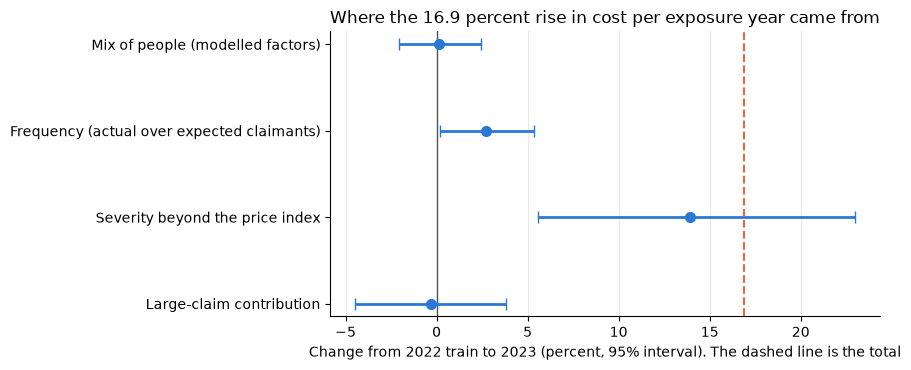

In [7]:
import matplotlib.pyplot as plt

shown = gap.iloc[:4]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axvline(0, color="#52514e", linewidth=1)
positions = range(len(shown))
ax.errorbar(
    shown["change_percent"],
    positions,
    xerr=[
        shown["change_percent"] - shown["lower_95_percent"],
        shown["upper_95_percent"] - shown["change_percent"],
    ],
    fmt="o",
    markersize=7,
    capsize=4,
    linewidth=2,
    color="#2a78d6",
)
ax.set_yticks(list(positions), shown["component"])
ax.invert_yaxis()
ax.axvline(gap["change_percent"].iloc[4], color="#eb6834", linestyle="--", linewidth=1.5)
ax.set_xlabel(
    "Change from 2022 train to 2023 (percent, 95% interval). The dashed line is the total"
)
ax.set_title("Where the 16.9 percent rise in cost per exposure year came from")
ax.grid(axis="x", color="#e8e8e6", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
figures.save_figure(fig, "gap_decomposition", outofsample.OUTPUT_DIR / "figures")
plt.show()

### Frequency by age group

The table shows the share of person-years with a claim and claims per exposure year in 2022 and 2023, for all person-years and for
children and three adult age groups, with the ratio of 2023 to 2022 train and a household interval. The actual-over-expected
columns adjust for the mix of people, because the expected claimants come from the model.

In [8]:
frequency = trend.frequency_table(frozen, oot)
outofsample.save_table(frequency, "frequency_by_age_group.csv")
frequency[
    [
        "group",
        "period",
        "person_years",
        "claimant_rate",
        "claims_per_exposure_year",
        "claimant_rate_vs_2022_train",
        "claimant_rate_vs_2022_train_lower_95",
        "claimant_rate_vs_2022_train_upper_95",
        "actual_over_expected_vs_2022_train",
        "actual_over_expected_vs_2022_train_lower_95",
        "actual_over_expected_vs_2022_train_upper_95",
    ]
]

,group,period,person_years,claimant_rate,claims_per_exposure_year,claimant_rate_vs_2022_train,claimant_rate_vs_2022_train_lower_95,claimant_rate_vs_2022_train_upper_95,actual_over_expected_vs_2022_train,actual_over_expected_vs_2022_train_lower_95,actual_over_expected_vs_2022_train_upper_95
0,All,2022 train,17596,0.409,3.057,NaN,NaN,NaN,NaN,NaN,NaN
1,All,2022 test,4151,0.416,3.040,NaN,NaN,NaN,NaN,NaN,NaN
2,All,2023,18463,0.420,3.343,1.028,0.998,1.058,1.027,1.002,1.053
3,Children,2022 train,3387,0.184,1.045,NaN,NaN,NaN,NaN,NaN,NaN
4,Children,2022 test,787,0.188,1.544,NaN,NaN,NaN,NaN,NaN,NaN
5,Children,2023,3556,0.193,1.470,1.046,0.930,1.162,1.054,0.940,1.170
6,18-39,2022 train,4260,0.262,1.589,NaN,NaN,NaN,NaN,NaN,NaN
7,18-39,2022 test,968,0.269,1.740,NaN,NaN,NaN,NaN,NaN,NaN
8,18-39,2023,4425,0.281,1.858,1.076,0.999,1.156,1.075,1.003,1.154
9,40-64,2022 train,5684,0.455,3.280,NaN,NaN,NaN,NaN,NaN,NaN


The share of person-years with a claim rose 2.8 percent (-0.2 to 5.8) and the mix-adjusted figure rose 2.7 percent (0.2 to 5.3).
Claims per exposure year rose more, by 9.3 percent (2.4 to 16.3), so people who claim made more claims as well. By age group, the
share with a claim rose 4.6 percent for children (-7.0 to 16.2), 7.6 percent for ages 18 to 39 (-0.1 to 15.6), 2.1 percent for 65 and
over (-0.8 to 5.2) and did not move for ages 40 to 64 (-0.2, with an interval of -4.4 to 4.2). No group is clearly outside sampling
noise, and the strongest movement is at ages 18 to 39.

### The 2023 A/E under each trend option

The table gives the A/E of 2023 (actual cost over predicted cost) for the technical model and the tariff under each option, with a
household interval. The trend the data imply is the hazard factor that makes the model's expected claimants match the claimants of
2023, given how well the model's frequency was calibrated on 2022 train. It is shown as a diagnostic and is not a forecast.

In [9]:
central = external[(external["market"] == "all") & (external["category"] == "blend")].iloc[0]
implied = trend.implied_hazard_factor(train_pieces, later_pieces)
source = "CMS URR PUF plan year 2023, Worksheet I, Year 2 utilization, blend"
options = {
    "(i) None (0 percent)": (1.0, "No trend", "Forecast candidate"),
    "(ii) External forecast, URR median": (central["p50"], source, "Forecast candidate"),
    "(ii) External forecast, URR lower quartile": (
        central["p25"],
        source,
        "Range for the sensitivity",
    ),
    "(ii) External forecast, URR upper quartile": (
        central["p75"],
        source,
        "Range for the sensitivity",
    ),
    "(iii) The trend the data imply": (
        implied,
        "Implied by the 2022 to 2023 data",
        "Diagnostic only, not a forecast",
    ),
}
trend_table = trend.trend_options(frozen, oot, options)
outofsample.save_table(trend_table, "trend_options_ae.csv")
trend_table

,option,hazard_factor,trend_percent,technical_a_e,technical_lower_95,technical_upper_95,tariff_a_e,tariff_lower_95,tariff_upper_95,source,use
0,(i) None (0 percent),1.000,0.000,1.167,1.095,1.243,1.167,1.095,1.243,No trend,Forecast candidate
1,"(ii) External forecast, URR median",1.019,1.900,1.155,1.084,1.231,1.155,1.084,1.230,"CMS URR PUF plan year 2023, Worksheet I, Year ...",Forecast candidate
2,"(ii) External forecast, URR lower quartile",1.008,0.826,1.162,1.090,1.238,1.162,1.090,1.237,"CMS URR PUF plan year 2023, Worksheet I, Year ...",Range for the sensitivity
3,"(ii) External forecast, URR upper quartile",1.031,3.076,1.148,1.077,1.223,1.148,1.077,1.223,"CMS URR PUF plan year 2023, Worksheet I, Year ...",Range for the sensitivity
4,(iii) The trend the data imply,1.046,4.573,1.139,1.069,1.214,1.139,1.069,1.213,Implied by the 2022 to 2023 data,"Diagnostic only, not a forecast"


Under no trend the technical model has an A/E of 1.167 on 2023 (interval 1.095 to 1.243), which means actual cost is 16.7 percent
above the prediction. With the external median (a hazard factor of 1.019, equal to a rise in cost of about 1.0 percent, because the
chance of a claim cannot rise by more than the hazard factor allows) the A/E is 1.155 (1.084 to 1.231). It is 1.162 at the lower
quartile (0.8 percent) and 1.148 at the upper quartile (3.1 percent). The trend that the data imply is a hazard factor of 1.046, and
even that leaves an A/E of 1.139 (1.069 to 1.214), because most of the gap is in the cost per claimant and not in the claim hazard.
The tariff gives the same A/E to three decimals, because it carries the same average rise.

The choice of forecast moves the A/E by about one point between none and the external median, which is far smaller than the gap and
smaller than the width of the interval. The conclusion does not depend on the choice. The trend the data imply is a diagnostic. It
is not used as a forecast.

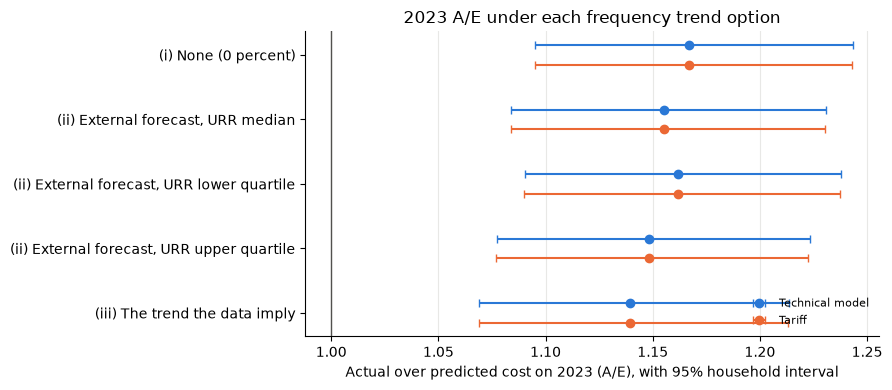

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvline(1.0, color="#52514e", linewidth=1)
labels = list(trend_table["option"])
for offset, model, colour, name in (
    (-0.15, "technical", "#2a78d6", "Technical model"),
    (0.15, "tariff", "#eb6834", "Tariff"),
):
    ax.errorbar(
        trend_table[f"{model}_a_e"],
        [k + offset for k in range(len(labels))],
        xerr=[
            trend_table[f"{model}_a_e"] - trend_table[f"{model}_lower_95"],
            trend_table[f"{model}_upper_95"] - trend_table[f"{model}_a_e"],
        ],
        fmt="o",
        markersize=6,
        capsize=3,
        linewidth=1.5,
        color=colour,
        label=name,
    )
ax.set_yticks(range(len(labels)), labels)
ax.invert_yaxis()
ax.set_xlabel("Actual over predicted cost on 2023 (A/E), with 95% household interval")
ax.set_title("2023 A/E under each frequency trend option")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="x", color="#e8e8e6", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
figures.save_figure(fig, "ae_by_trend_option", outofsample.OUTPUT_DIR / "figures")
plt.show()

### How much of the gap is the large-claim load

The provisional load of 6.5 percent comes from 2022 train. The cost above the cap in 2023 is 6.2 percent of capped cost. The table
shows how much the A/E would change if the load matched the 2023 excess. Nothing is tuned for it, and the load is re-estimated later.

In [11]:
own_load = oot.frame["cost"].sum() / oot.frame["capped_cost"].sum() - 1
load = trend.load_check(frozen, later_pieces, float(own_load))
outofsample.save_table(pd.DataFrame([load]), "load_check_2023.csv")
pd.DataFrame([load])

,a_e_provisional_load,own_excess_load,provisional_load,a_e_if_load_matched,change_in_a_e_points
0,1.167,0.062,0.065,1.171,0.369


The provisional load is already above the cost over the cap that 2023 shows (6.5 against 6.2 percent), so none of the A/E gap is
consistent with it. With a load that matched 2023 the A/E would be 1.171, which is 0.4 points higher. The load is not tuned and it
is re-estimated later.

### The A/E as a product of its parts

Both models are balanced on 2022 train, so their A/E on train is 1. The A/E of the technical model on 2023 is therefore the product
of the frequency, severity and large-claim ratios of 2023 to train, and the mix of people cancels out.

In [12]:
components = trend.ae_components(frozen, oot, train_pieces, later_pieces)
outofsample.save_table(components, "ae_components_2023.csv")
components

,measure,value,lower_95,upper_95
0,Technical model A/E,1.167,1.095,1.243
1,Tariff A/E,1.167,1.095,1.243
2,Frequency (actual over expected claimants),1.027,1.002,1.053
3,Severity beyond the price index,1.139,1.056,1.230
4,Large-claim contribution,0.997,0.955,1.038


### For the gate: the forecast trend

**Evidence.** The 2023 gap in cost per exposure year is 16.9 percent, of which 13.9 percent is severity beyond the price index and
2.7 percent is frequency. A forecast of the frequency trend can therefore change the 2023 A/E by about one point and cannot
close a gap of 16.7 percent.

**Options for the forecast assumption.**

| Option | Hazard factor | Technical model A/E | Source |
|---|---|---|---|
| (i) None | 1.000 | 1.167 | No trend |
| (ii) External, URR median | 1.019 | 1.155 | CMS URR PUF plan year 2023, Worksheet I, Year 2 utilization, blend, filings made in 2022 |
| (iii) The trend the data imply | 1.046 | 1.139 | Diagnostic only. It is not an allowed forecast |

**Recommendation.** Option (ii), the external median of 1.9 percent as the central forecast, with 0.8 and 3.1 percent as the range
for the sensitivity task. It is a pre-2023, independent actuarial view, and it makes the out-of-time test a test of a forecast that a
pricing team could have made. Option (i) gives the same conclusion to within one point of A/E, and is the fallback if the user
prefers not to use a figure from another market. The data-implied trend is never used.

**For the user to decide.** The central forecast trend for the out-of-time test.